In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmcrameri import cm
import seaborn as sns
import pennylane as qml
import jax.numpy as jnp
import re
import os, sys
sys.path.append('../')
from libs import circuits
plt.style.use('../libs/notebookstyle_aps.mplstyle')

%load_ext autoreload
%autoreload 2

In [3]:
dfq = pd.read_csv('../results/QNN_results/QNN_r2.txt', header =0, index_col = None)

def parse_config(s):
    match = re.match(r"(\d+)qubits_circuit_([a-zA-Z]+)_([a-zA-Z]+)_freq(\d+)enc_(\d+)dec_([a-zA-Z]+)", s)
    if match:
        qubits, enc_angles, angles, n_enc, n_dec,  entanglement = match.groups()
        return int(qubits), int(n_enc), int(n_dec), entanglement, angles, enc_angles
    return None, None, None, None

dfq[['n_qubits', 'n_enc', 'n_dec', 'entanglement','angles','enc_angles']] = dfq['model_name'].apply(
    lambda x: pd.Series(parse_config(x))
)

dfq['nonlocal'] = (dfq.entanglement == 'nonlocal')*1.
dfq['n_params'] = dfq.n_qubits*(dfq.n_enc + dfq.n_dec)*dfq.angles.apply(lambda s: len(s)) + dfq.n_qubits*dfq.n_enc*dfq.enc_angles.apply(lambda s: len(s))

## Plotting a circuit

In [4]:
# ---- pick the model to draw -------------------------------------------
n_qubits         = 2
n_enc, n_dec     = 2, 1
var_angles       = "XYZ"
encoding_angles  = "XYZ" 
choose_freq      = True

circuit = circuits.PQCircuit(n_enc, n_dec, n_qubits,
                             var_angles=var_angles,
                             encoding_angles=encoding_angles,
                             choose_freq=choose_freq)
dev = qml.device("default.qubit", wires=n_qubits)

# total number of variational+encoding angles (same rule as make_model)
no_params = circuit.n_var_angles + (circuit.n_encoding_angles if circuit.choose_freq else 0)

@qml.qnode(dev, interface="jax")
def qnn_pqc(inputs, angles):
    circuit(inputs, angles, dev.wires)
    return [qml.expval(qml.PauliZ(0))]


print(qml.draw(qnn_pqc)(jnp.arange(6)[None,:], jnp.ones(no_params)))

# ---- pick the model to draw -------------------------------------------
n_qubits         = 4
n_enc, n_dec     = 2, 1
var_angles       = "XYZ"
encoding_angles  = "XYZ" 
choose_freq      = True

circuit = circuits.PQCircuit(n_enc, n_dec, n_qubits,
                             var_angles=var_angles,
                             encoding_angles=encoding_angles,
                             choose_freq=choose_freq)
dev = qml.device("default.qubit", wires=n_qubits)

# total number of variational+encoding angles (same rule as make_model)
no_params = circuit.n_var_angles + (circuit.n_encoding_angles if circuit.choose_freq else 0)

@qml.qnode(dev, interface="jax")
def qnn_pqc(inputs, angles):
    circuit(inputs, angles, dev.wires)
    return [qml.expval(qml.PauliZ(0))]


print(qml.draw(qnn_pqc)(jnp.arange(6)[None,:], jnp.ones(no_params)))

# ---- pick the model to draw -------------------------------------------
n_qubits         = 6
n_enc, n_dec     = 2, 1
var_angles       = "XYZ"
encoding_angles  = "XY" 
choose_freq      = True

circuit = circuits.PQCircuit(n_enc, n_dec, n_qubits,
                             var_angles=var_angles,
                             encoding_angles=encoding_angles,
                             choose_freq=choose_freq)
dev = qml.device("default.qubit", wires=n_qubits)

# total number of variational+encoding angles (same rule as make_model)
no_params = circuit.n_var_angles + (circuit.n_encoding_angles if circuit.choose_freq else 0)

@qml.qnode(dev, interface="jax")
def qnn_pqc(inputs, angles):
    circuit(inputs, angles, dev.wires)
    return [qml.expval(qml.PauliZ(0))]


print(qml.draw(qnn_pqc)(jnp.arange(6)[None,:], jnp.ones(no_params)))

0: ─╭AngleEmbedding(M0)─╭AngleEmbedding(M1)─╭AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─╭● ···
1: ─╰AngleEmbedding(M0)─╰AngleEmbedding(M1)─╰AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─╰X ···

0: ··· ─╭X─╭AngleEmbedding(M0)─╭AngleEmbedding(M1)─╭AngleEmbedding(M2)──RX(1.00)──RY(1.00) ···
1: ··· ─╰●─╰AngleEmbedding(M0)─╰AngleEmbedding(M1)─╰AngleEmbedding(M2)──RX(1.00)──RY(1.00) ···

0: ··· ──RZ(1.00)─╭●─╭X──RX(1.00)──RY(1.00)──RZ(1.00)─╭●─╭X─┤  <Z>
1: ··· ──RZ(1.00)─╰X─╰●──RX(1.00)──RY(1.00)──RZ(1.00)─╰X─╰●─┤     

M0 = 
[[0. 1.]]
M1 = 
[[2. 3.]]
M2 = 
[[4. 5.]]
0: ─╭AngleEmbedding(M0)─╭AngleEmbedding(M1)─╭AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─╭● ···
1: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)─├AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─╰X ···
2: ─├AngleEmbedding(M0)─├AngleEmbedding(M1)─├AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─── ···
3: ─╰AngleEmbedding(M0)─╰AngleEmbedding(M1)─╰AngleEmbedding(M2)──RX(1.00)──RY(1.00)──RZ(1.00)─── ···

0: ··· ───────╭X─╭

## Figure with Overview of validation R² for SI

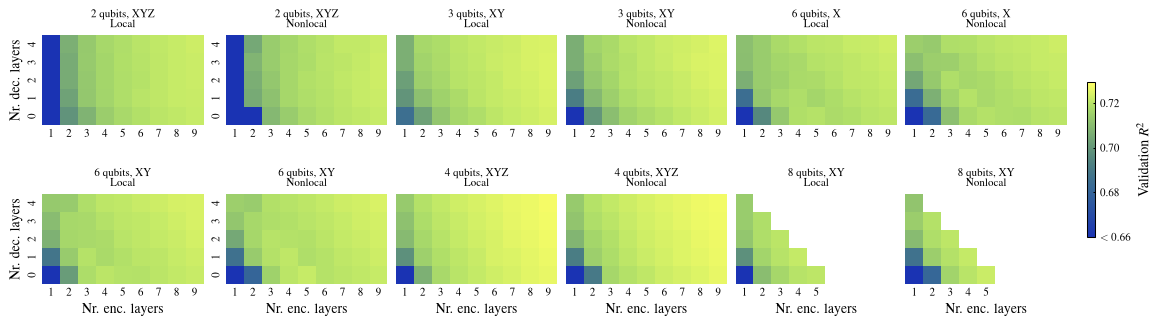

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.ticker import MaxNLocator, FormatStrFormatter, FuncFormatter
import seaborn as sns

fig, axs = plt.subplots(
    2, 6,
    figsize=(11.5, 3.2),
    constrained_layout=True,
)
configs = [
    dict(n_qubits=2, enc_angles="XYZ", label="2 qubits, XYZ"),
    dict(n_qubits=3, enc_angles="XY",  label="3 qubits, XY"),
    dict(n_qubits=6, enc_angles="X",   label="6 qubits, X"),
    dict(n_qubits=6, enc_angles="XY",  label="6 qubits, XY"),
    dict(n_qubits=4, enc_angles="XYZ", label="4 qubits, XYZ"),
    dict(n_qubits=8, enc_angles="XY",  label="8 qubits, XY"),
]
# one norm object, used for heatmaps & the colorbar so they always agree
vmin, vmax = 0.66, dfq.r2_val.max()
norm = Normalize(vmin, vmax)

for row in range(2):
    # per-row grid: each row only spans the enc/dec values it actually has
    row_cfgs = configs[3 * row: 3 * row + 3]
    dfrow = pd.concat([
        dfq[(dfq.n_qubits == cfg["n_qubits"]) & (dfq.enc_angles == cfg["enc_angles"])]
        for cfg in row_cfgs
    ])
    enc_vals = np.sort(dfrow.n_enc.unique())
    dec_vals = np.sort(dfrow.n_dec.unique())

    for j, cfg in enumerate(row_cfgs):
        c = j * 2
        ax_local = axs[row, c]
        ax_nonlocal = axs[row, c + 1]

        dfsub = dfq[(dfq.n_qubits == cfg["n_qubits"]) & (dfq.enc_angles == cfg["enc_angles"])]

        for ax, kind in [(ax_local, "Local"), (ax_nonlocal, "Nonlocal")]:
            
            pivot = dfsub[dfsub["nonlocal"] == (0 if kind == "Local" else 1)].pivot_table(
                columns="n_enc", index="n_dec", values="r2_val", aggfunc="mean"
            ).reindex(index=dec_vals, columns=enc_vals)
            if pivot.empty or not pivot.notna().any().any():
                ax.set_axis_off()
                continue
            sns.heatmap(
                pivot, ax=ax, cmap=cm.imola,
                norm=norm,
                cbar=False,
                square=True,
            )
            ax.set_title(f"{cfg['label']}\n{kind}", fontsize=8)
            ax.invert_yaxis()

            col_has = pivot.notna().any(axis=0)
            row_has = pivot.notna().any(axis=1)
            
            ax.set_xticks(np.arange(len(enc_vals)) + 0.5)
            ax.set_xticklabels([str(int(v)) if (col_has.iloc[i]) else "" for i, v in enumerate(enc_vals)]) #row == 1 and 
            ax.set_yticks(np.arange(len(dec_vals)) + 0.5)
            ax.set_yticklabels([str(int(v)) if (c == 0 and row_has.iloc[i] and j == 0) else "" for i, v in enumerate(dec_vals)])
            ax.tick_params(length=0, pad=3)

            ax.set_xlabel("Nr. enc. layers" if (row == 1) else "")
            ax.set_ylabel("Nr. dec. layers" if (c == 0)&(j == 0)&(kind == 'Local') else "")

sm = plt.cm.ScalarMappable(cmap=cm.imola, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=axs, aspect=20, pad=0.02, shrink=0.5)
cbar.ax.yaxis.set_ticks([0.66,0.68, 0.7, 0.72])

def format_cbar(x, pos):
    if x <= 0.66:
        return "$<0.66$"
    return f"{x:.2f}"

cbar.ax.yaxis.set_major_formatter(FuncFormatter(format_cbar))
cbar.set_label("Validation $R^2$")
cbar.ax.tick_params(length=1.5)

fig.savefig("../figures/QNN_layers.pdf", bbox_inches="tight")

## Plotting training histories

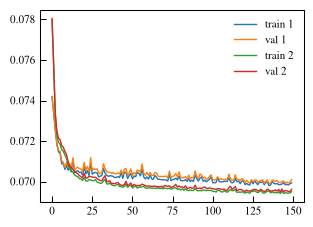

In [17]:
hist = np.load('../results/QNN_results/2qubits_circuit_XYZ_XYZ_freq6enc_2dec_nonlocal_historykey_392068016_1989062420.npz', allow_pickle = True)['history'].item()
plt.plot(hist['train_loss'], label = 'train 1')
plt.plot(hist['val_loss'], label = 'val 1')

hist = np.load('../results/QNN_results/8qubits_circuit_XY_XYZ_freq4enc_1dec_nonlocal_historykey_392068016_1989062420.npz', allow_pickle = True)['history'].item()
plt.plot(hist['train_loss'], label = 'train 2')
plt.plot(hist['val_loss'], label = 'val 2')

plt.legend()
